Simple visualizer for log files written by the training loop

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

In [6]:
log_file_run = "first_attempt"
log_file_name = f"../my_logs/{log_file_run}/main.log"

In [7]:
def parse_logfile(logfile):
    # so the tricky part we have to deal with in these log files
    # is that the job could crash and get restarted, which will
    # re-wind back and start re-logging older steps. So we keep
    # all the data as dictionary and over-write old data with new
    # and then at the end compile everything together

    # read raw data
    streams = {} # stream:str -> {step: val}
    with open(logfile, "r") as f:
        for line in f:
            parts = line.split()
            step = int(parts[0].split(":")[1])
            stream = parts[1].split(":")[0]
            val = float(parts[1].split(":")[1])
            if not stream in streams:
                streams[stream] = {}
            d = streams[stream]
            d[step] = val
    # now re-represent as list of (step, val) tuples
    streams_xy = {}
    for k, v in streams.items():
        # get all (step, val) items, sort them
        xy = sorted(list(v.items()))
        # unpack the list of tuples to tuple of lists
        streams_xy[k] = zip(*xy)
    # return the xs, ys lists
    return streams_xy

parse_logfile(log_file_name)

{'tel': <zip at 0x7ac8a4c22c80>, 'trl': <zip at 0x7ac8a4c22d00>}

Min Train Loss: 9.0035
Min Validation Loss: 8.9818


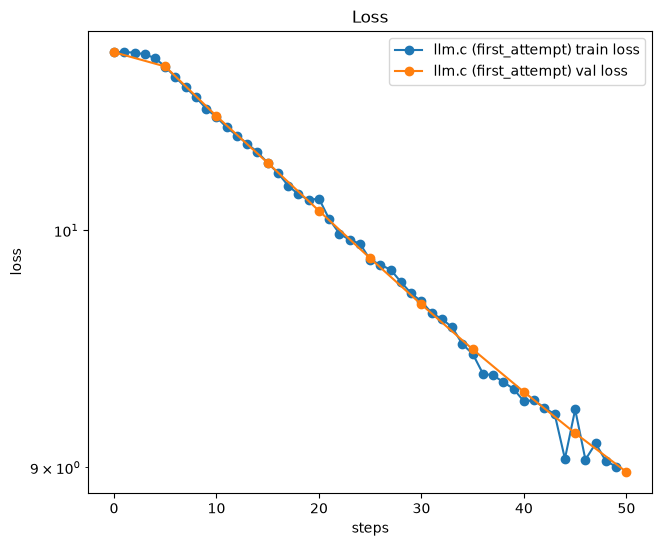

In [19]:
import numpy as np

# assumes each model run is stored in this way
streams = parse_logfile(log_file_name)

# optional function that smooths out the loss some
def smooth_moving_average(signal, window_size):
    if signal.ndim != 1:
        raise ValueError("smooth_moving_average only accepts 1D arrays.")
    if signal.size < window_size:
        raise ValueError("Input vector needs to be bigger than window size.")
    if window_size < 3:
        return signal

    s = np.pad(signal, (window_size//2, window_size-1-window_size//2), mode='edge')
    w = np.ones(window_size) / window_size
    smoothed_signal = np.convolve(s, w, mode='valid')
    return smoothed_signal

plt.figure(figsize=(16, 6))

# Panel 1: losses: both train and val
plt.subplot(121)
xs, ys = streams["trl"] # training loss
ys = np.array(ys)
# smooth out ys using a rolling window
# ys = smooth_moving_average(ys, 21) # optional
plt.plot(xs, ys, marker='o', label=f'llm.c ({log_file_run}) train loss')
print("Min Train Loss:", min(ys))
xs, ys = streams["tel"] # validation loss
plt.plot(xs, ys, marker='o', label=f'llm.c ({log_file_run}) val loss')
plt.xlabel("steps")
plt.ylabel("loss")
plt.yscale('log')
plt.legend()
plt.title("Loss")
print("Min Validation Loss:", min(ys))